In [ ]:

import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras import regularizers
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.metrics import roc_curve, auc



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

import pandas as pd
import time

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)



In [3]:
DATA_DIR = Path(r"C:\Users\vladl\Desktop\ТГУ\4 курс\нейронные сети\лаб3\PlantVillage")

In [4]:

classes = {
    0: "Tomato__Tomato_YellowLeaf__Curl_Virus",
    1: "Tomato_healthy",
    2: "Tomato_Septoria_leaf_spot"
}

image_extensions = {".jpg", ".jpeg", ".png"}

images = {}

for label, class_name in classes.items():
    folder = DATA_DIR / class_name

    files = [
        file for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    images[label] = files

    print(f"Класс {label}: {class_name}")
    print(f"Количество изображений: {len(files)}")
    print()

print("Всего изображений:", sum(len(files) for files in images.values()))


Класс 0: Tomato__Tomato_YellowLeaf__Curl_Virus
Количество изображений: 3208

Класс 1: Tomato_healthy
Количество изображений: 1591

Класс 2: Tomato_Septoria_leaf_spot
Количество изображений: 1771

Всего изображений: 6570


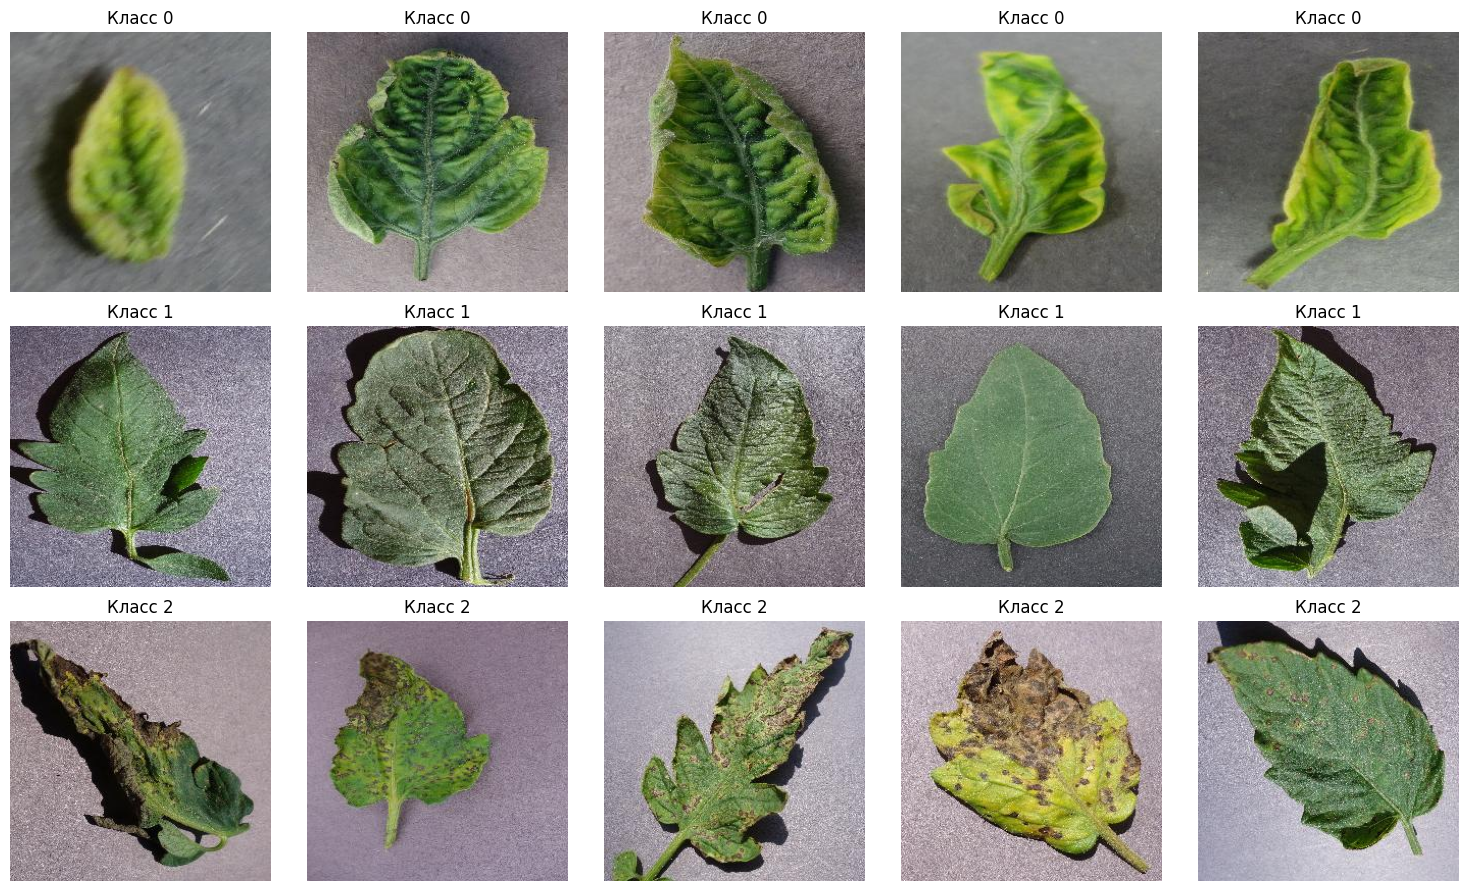

In [5]:

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for label, class_name in classes.items():
    selected_images = random.sample(images[label], min(5, len(images[label])))

    for i, image_path in enumerate(selected_images):
        with Image.open(image_path) as img:
            image = img.convert("RGB")
        axes[label, i].imshow(image)
        axes[label, i].set_title(f"Класс {label}")
        axes[label, i].axis("off")

plt.tight_layout()
plt.show()


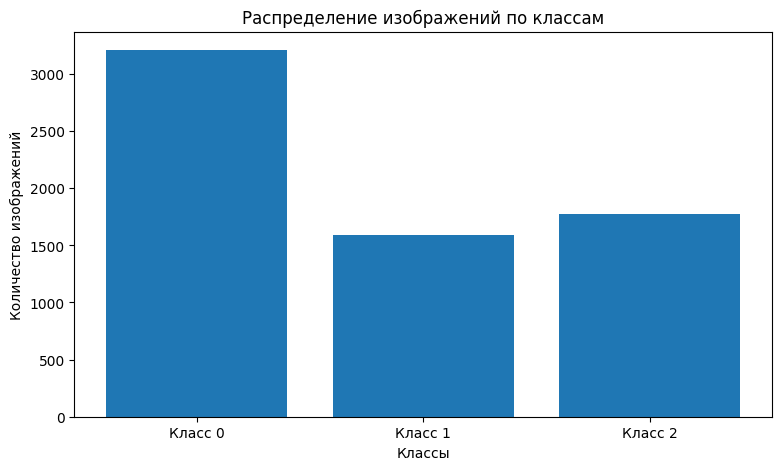

In [6]:

class_counts = [len(images[label]) for label in classes]

plt.figure(figsize=(9, 5))

plt.bar(
    [f"Класс {label}" for label in classes],
    class_counts
)

plt.title("Распределение изображений по классам")
plt.xlabel("Классы")
plt.ylabel("Количество изображений")

plt.show()


In [7]:

valid_images = {}
damaged_images = []

for label, files in images.items():
    valid_images[label] = []

    for file in files:
        try:
            with Image.open(file) as img:
                img.verify()

            valid_images[label].append(file)

        except Exception:
            damaged_images.append(file)

for label in classes:
    print(f"Класс {label}: {len(valid_images[label])} исправных изображений")

print("Повреждённых изображений:", len(damaged_images))


Класс 0: 3208 исправных изображений
Класс 1: 1591 исправных изображений
Класс 2: 1771 исправных изображений
Повреждённых изображений: 0


In [8]:

file_paths = []
labels = []

for label, files in valid_images.items():
    for file in files:
        file_paths.append(str(file))
        labels.append(label)

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    file_paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

print("Обучающая:", len(train_paths))
print("Валидационная:", len(val_paths))
print("Тестовая:", len(test_paths))


Обучающая: 4599
Валидационная: 985
Тестовая: 986


In [9]:

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape((None, None, 3))
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

def create_dataset(paths, labels, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(paths), seed=SEED)

    dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = create_dataset(train_paths, train_labels, shuffle=True)
val_ds = create_dataset(val_paths, val_labels)
test_ds = create_dataset(test_paths, test_labels)



Вобщем нужно было преобразовать картинку в размер 224*224 и разбил на пакеты по 32 изображения в пакете. 

Также перевел в  RGB  и нормализировал пиксели ( то есть поделил на 255)

In [10]:

def create_binary_data(paths, labels):
    binary_paths = []
    binary_labels = []

    for path, label in zip(paths, labels):
        if label in [0, 1]:
            binary_paths.append(path)
            binary_labels.append(label)

    return binary_paths, binary_labels

train_binary_paths, train_binary_labels = create_binary_data(train_paths, train_labels)

val_binary_paths, val_binary_labels = create_binary_data(val_paths, val_labels)

test_binary_paths, test_binary_labels = create_binary_data(test_paths, test_labels)

train_binary_ds = create_dataset(train_binary_paths, train_binary_labels, shuffle=True)

val_binary_ds = create_dataset(val_binary_paths, val_binary_labels)

test_binary_ds = create_dataset(test_binary_paths, test_binary_labels)

print("Обучающая:", len(train_binary_paths))
print("Валидационная:", len(val_binary_paths))
print("Тестовая:", len(test_binary_paths))


Обучающая: 3359
Валидационная: 720
Тестовая: 720


Для задачи с бинарной классификацией нужно убрать 3 класс с заболеванием. 

Но для этого я создаю новые датасеты и не менял старые ( то есть для   бинарной нужно брать  binary а для трехклассовой квалификацией  нужно просто paths)

In [11]:

cnn1 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

cnn1.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,907,521 (91.20 MB)

 Trainable params: 23,907,521 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:

cnn1.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="binary_crossentropy",
            metrics=["accuracy"]
)


In [13]:

early_stop = EarlyStopping(
                            monitor="val_loss",
                            patience=5,
                            restore_best_weights=True
                        )

checkpoint = ModelCheckpoint(
                            "cnn1_best.keras",
                            monitor="val_loss",
                            save_best_only=True
                        )

start_time = time.time()

history1 = cnn1.fit(
                    train_binary_ds,
                    validation_data=val_binary_ds,
                    epochs=20,
                    callbacks=[early_stop, checkpoint]
                    )

train_time1 = time.time() - start_time

print(f"Время обучения: {train_time1:.1f} секунд")


Epoch 1/20


c:\Users\vladl\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


105/105 ━━━━━━━━━━━━━━━━━━━━ 26s 232ms/step - accuracy: 0.9229 - loss: 0.3932 - val_accuracy: 0.9958 - val_loss: 0.0130
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 58s 558ms/step - accuracy: 0.9961 - loss: 0.0159 - val_accuracy: 0.9917 - val_loss: 0.0379
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 46s 208ms/step - accuracy: 0.9932 - loss: 0.0202 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 22s 208ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 0.0010
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 63s 604ms/step - accuracy: 0.9991 - loss: 0.0019 - val_accuracy: 1.0000 - val_loss: 6.6279e-04
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 90s 676ms/step - accuracy: 1.0000 - loss: 3.0113e-04 - val_accuracy: 1.0000 - val_loss: 6.3715e-04
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 69s 654ms/step - accuracy: 1.0000 - loss: 2.8989e-04 - val_accuracy: 1.0000 - val_loss: 6.7533e-04
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 69s 659ms/step - accuracy: 1.0000 

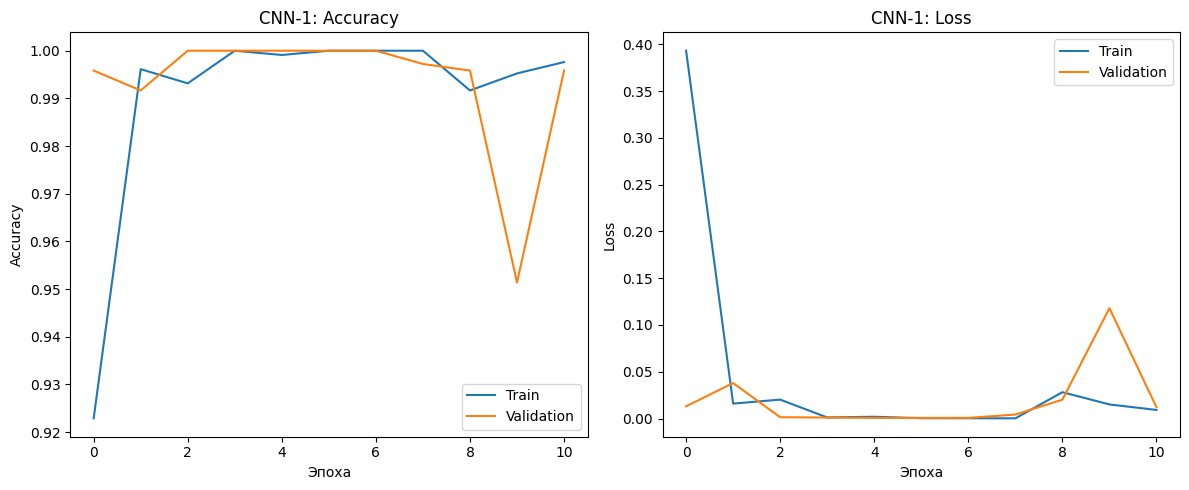

In [14]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history1.history["accuracy"], label="Train")
plt.plot(history1.history["val_accuracy"], label="Validation")
plt.title("CNN-1: Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history1.history["loss"], label="Train")
plt.plot(history1.history["val_loss"], label="Validation")
plt.title("CNN-1: Loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [15]:

cnn2 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

cnn2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:

cnn2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [20]:

early_stop2 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint2 = ModelCheckpoint(
    "cnn2_best.keras",
    monitor="val_loss",
    save_best_only=True
)

start_time = time.time()

history2 = cnn2.fit(
    train_binary_ds,
    validation_data=val_binary_ds,
    epochs=20,
    callbacks=[early_stop2, checkpoint2]
)

train_time2 = time.time() - start_time

print(f"Время обучения CNN-2: {train_time2:.1f} секунд")


Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 76s 724ms/step - accuracy: 0.8416 - loss: 0.3417 - val_accuracy: 0.9667 - val_loss: 0.1253
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 103s 925ms/step - accuracy: 0.9675 - loss: 0.0885 - val_accuracy: 0.9667 - val_loss: 0.0936
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 73s 697ms/step - accuracy: 0.9756 - loss: 0.0657 - val_accuracy: 0.9708 - val_loss: 0.0846
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 96s 919ms/step - accuracy: 0.9842 - loss: 0.0421 - val_accuracy: 0.9750 - val_loss: 0.0857
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 68s 649ms/step - accuracy: 0.9881 - loss: 0.0294 - val_accuracy: 0.9778 - val_loss: 0.0763
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 111s 922ms/step - accuracy: 0.9887 - loss: 0.0329 - val_accuracy: 0.9778 - val_loss: 0.0800
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 80s 764ms/step - accuracy: 0.9905 - loss: 0.0292 - val_accuracy: 0.9819 - val_loss: 0.0669
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 91s 870ms/step - accuracy: 0.9902 - loss:

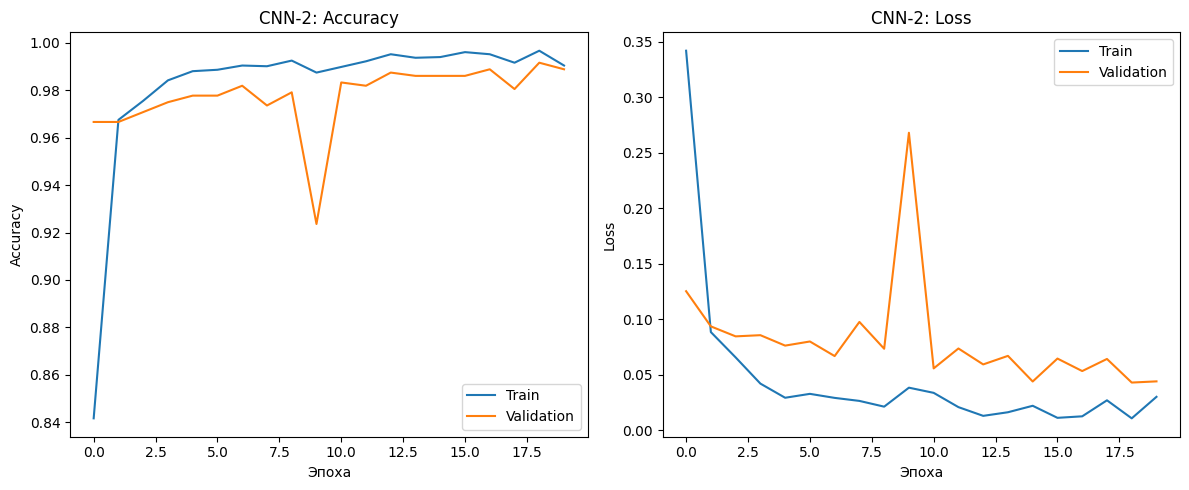

In [21]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history2.history["accuracy"], label="Train")
plt.plot(history2.history["val_accuracy"], label="Validation")

plt.title("CNN-2: Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history2.history["loss"], label="Train")
plt.plot(history2.history["val_loss"], label="Validation")

plt.title("CNN-2: Loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [22]:


results = pd.DataFrame({
    "Модель": ["CNN-1", "CNN-2"],
    "Лучшая val_accuracy": [
        max(history1.history["val_accuracy"]),
        max(history2.history["val_accuracy"])
    ],
    "Минимальная val_loss": [
        min(history1.history["val_loss"]),
        min(history2.history["val_loss"])
    ],
    "Время обучения (с)": [
        train_time1,
        train_time2
    ]
})

print(results.round(4))


  Модель  Лучшая val_accuracy  Минимальная val_loss  Время обучения (с)
0  CNN-1               1.0000                0.0006            661.1591
1  CNN-2               0.9917                0.0430           1581.8401


In [24]:

cnn3 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

cnn3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:

cnn3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [26]:

early_stop3 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint3 = ModelCheckpoint(
    "cnn3_best.keras",
    monitor="val_loss",
    save_best_only=True
)

start_time = time.time()

history3 = cnn3.fit(
    train_binary_ds,
    validation_data=val_binary_ds,
    epochs=20,
    callbacks=[early_stop3, checkpoint3]
)

train_time3 = time.time() - start_time

print(f"Время обучения CNN-3: {train_time3:.1f} секунд")

Epoch 1/20


c:\Users\vladl\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


105/105 ━━━━━━━━━━━━━━━━━━━━ 84s 797ms/step - accuracy: 0.8821 - loss: 0.3346 - val_accuracy: 0.9653 - val_loss: 0.1499
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 97s 924ms/step - accuracy: 0.9881 - loss: 0.0754 - val_accuracy: 0.9792 - val_loss: 0.0923
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 142s 927ms/step - accuracy: 0.9926 - loss: 0.0494 - val_accuracy: 0.9806 - val_loss: 0.0901
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 97s 924ms/step - accuracy: 0.9914 - loss: 0.0464 - val_accuracy: 0.9625 - val_loss: 0.1370
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 131s 817ms/step - accuracy: 0.9935 - loss: 0.0376 - val_accuracy: 0.9917 - val_loss: 0.0522
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 153s 923ms/step - accuracy: 0.9875 - loss: 0.0506 - val_accuracy: 0.9889 - val_loss: 0.0598
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 73s 697ms/step - accuracy: 0.9958 - loss: 0.0265 - val_accuracy: 0.9931 - val_loss: 0.0466
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 99s 855ms/step - accuracy: 0.9920 - loss: 0.0331 - 

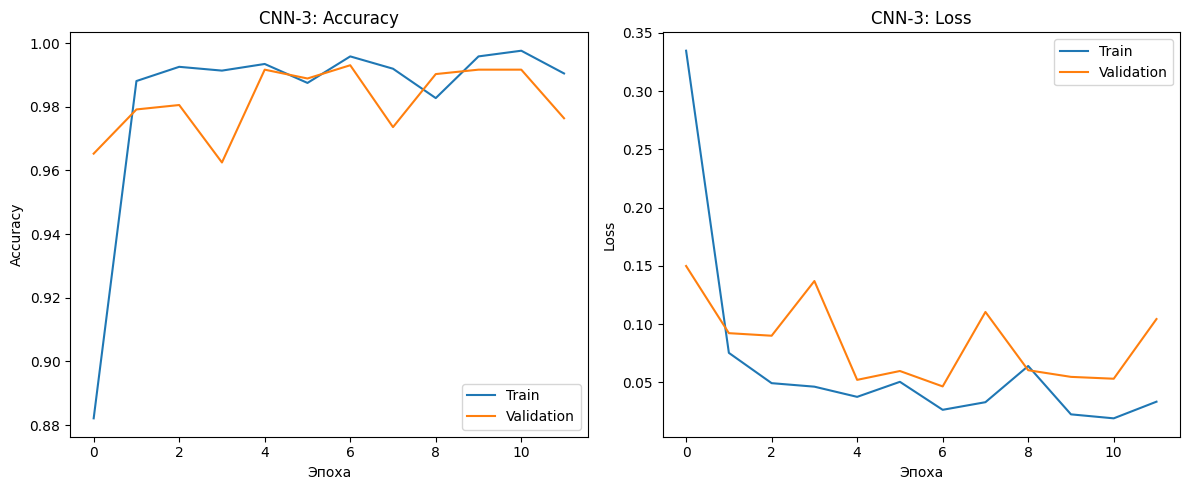

In [27]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history3.history["accuracy"], label="Train")
plt.plot(history3.history["val_accuracy"], label="Validation")

plt.title("CNN-3: Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history3.history["loss"], label="Train")
plt.plot(history3.history["val_loss"], label="Validation")

plt.title("CNN-3: Loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [28]:

results = pd.DataFrame({
    "Модель": ["CNN-1", "CNN-2", "CNN-3"],

    "Лучшая val_accuracy": [
        max(history1.history["val_accuracy"]),
        max(history2.history["val_accuracy"]),
        max(history3.history["val_accuracy"])
    ],

    "Минимальная val_loss": [
        min(history1.history["val_loss"]),
        min(history2.history["val_loss"]),
        min(history3.history["val_loss"])
    ],

    "Эпох обучения": [
        len(history1.history["loss"]),
        len(history2.history["loss"]),
        len(history3.history["loss"])
    ],

    "Время (с)": [
        train_time1,
        train_time2,
        train_time3
    ]
})

print(results.round(4))

  Модель  Лучшая val_accuracy  Минимальная val_loss  Эпох обучения  Время (с)
0  CNN-1               1.0000                0.0006             11   661.1591
1  CNN-2               0.9917                0.0430             20  1581.8401
2  CNN-3               0.9931                0.0466             12  1253.3741


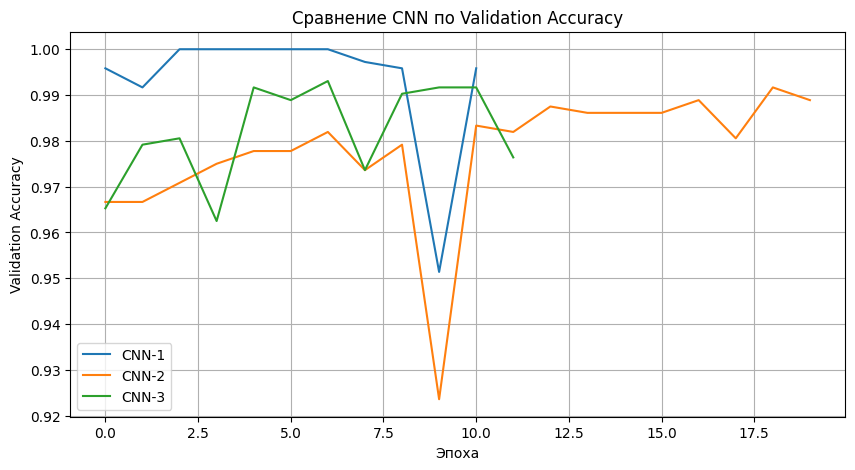

In [29]:

plt.figure(figsize=(10, 5))

plt.plot(
    history1.history["val_accuracy"],
    label="CNN-1"
)

plt.plot(
    history2.history["val_accuracy"],
    label="CNN-2"
)

plt.plot(
    history3.history["val_accuracy"],
    label="CNN-3"
)

plt.title("Сравнение CNN по Validation Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [30]:

models_info = {
    "CNN-1": {
        "model": cnn1,
        "history": history1
    },
    "CNN-2": {
        "model": cnn2,
        "history": history2
    },
    "CNN-3": {
        "model": cnn3,
        "history": history3
    }
}

best_name = min(
    models_info,
    key=lambda name: min(
        models_info[name]["history"].history["val_loss"]
    )
)

best_model = models_info[best_name]["model"]

print("Лучшая модель:", best_name)
print(
    "Минимальная val_loss:",
    min(models_info[best_name]["history"].history["val_loss"])
)

Лучшая модель: CNN-1
Минимальная val_loss: 0.0006371458875946701


In [31]:

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05)
])


In [32]:

cnn_aug = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

cnn_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_aug.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,907,521 (91.20 MB)

 Trainable params: 23,907,521 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:

early_stop_aug = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint_aug = ModelCheckpoint(
    "cnn_aug_best.keras",
    monitor="val_loss",
    save_best_only=True
)

start_time = time.time()

history_aug = cnn_aug.fit(
    train_binary_ds,
    validation_data=val_binary_ds,
    epochs=20,
    callbacks=[early_stop_aug, checkpoint_aug]
)

train_time_aug = time.time() - start_time

print(f"Время обучения: {train_time_aug:.1f} секунд")


Epoch 1/20


c:\Users\vladl\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


105/105 ━━━━━━━━━━━━━━━━━━━━ 85s 806ms/step - accuracy: 0.9547 - loss: 0.1978 - val_accuracy: 0.9806 - val_loss: 0.0435
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 144s 829ms/step - accuracy: 0.9935 - loss: 0.0181 - val_accuracy: 0.9542 - val_loss: 0.1179
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 79s 754ms/step - accuracy: 0.9893 - loss: 0.0317 - val_accuracy: 0.9903 - val_loss: 0.0246
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 81s 778ms/step - accuracy: 0.9943 - loss: 0.0209 - val_accuracy: 0.9972 - val_loss: 0.0044
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 79s 745ms/step - accuracy: 0.9929 - loss: 0.0194 - val_accuracy: 0.9944 - val_loss: 0.0102
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 88s 834ms/step - accuracy: 0.9932 - loss: 0.0198 - val_accuracy: 0.9972 - val_loss: 0.0202
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 143s 843ms/step - accuracy: 0.9973 - loss: 0.0092 - val_accuracy: 0.9889 - val_loss: 0.0230
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 143s 849ms/step - accuracy: 0.9979 - loss: 0.0062 - 

In [34]:

aug_results = pd.DataFrame({
    "Модель": ["CNN-1", "CNN + Augmentation"],

    "Лучшая val_accuracy": [
        max(history1.history["val_accuracy"]),
        max(history_aug.history["val_accuracy"])
    ],

    "Минимальная val_loss": [
        min(history1.history["val_loss"]),
        min(history_aug.history["val_loss"])
    ],

    "Эпох обучения": [
        len(history1.history["loss"]),
        len(history_aug.history["loss"])
    ],

    "Время (с)": [
        train_time1,
        train_time_aug
    ]
})

print(aug_results.round(4))


               Модель  Лучшая val_accuracy  Минимальная val_loss  \
0               CNN-1                  1.0                0.0006   
1  CNN + Augmentation                  1.0                0.0020   

   Эпох обучения  Время (с)  
0             11   661.1591  
1             13  1199.6446  


In [59]:

binary_models = {
    "CNN-1": "cnn1_best.keras",
    "CNN + Augmentation": "cnn_aug_best.keras"
}

y_true = np.array(test_binary_labels)

binary_results = []
binary_predictions = {}

for name, model_path in binary_models.items():
    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    y_prob = model.predict(
        test_binary_ds,
        verbose=0
    ).ravel()

    y_pred = (y_prob >= 0.5).astype(int)

    binary_predictions[name] = (y_pred, y_prob)

    binary_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    })

    print("\nМодель:", name)
    print(classification_report(
        y_true,
        y_pred,
        target_names=["Больной", "Здоровый"],
        digits=4,
        zero_division=0
    ))

binary_results = pd.DataFrame(binary_results)

print("\nИтоговое сравнение:")
print(binary_results.round(4))


Модель: CNN-1
              precision    recall  f1-score   support

     Больной     1.0000    1.0000    1.0000       482
    Здоровый     1.0000    1.0000    1.0000       238

    accuracy                         1.0000       720
   macro avg     1.0000    1.0000    1.0000       720
weighted avg     1.0000    1.0000    1.0000       720


Модель: CNN + Augmentation
              precision    recall  f1-score   support

     Больной     1.0000    1.0000    1.0000       482
    Здоровый     1.0000    1.0000    1.0000       238

    accuracy                         1.0000       720
   macro avg     1.0000    1.0000    1.0000       720
weighted avg     1.0000    1.0000    1.0000       720


Итоговое сравнение:
               Модель  Accuracy  Precision  Recall  F1-score  ROC-AUC
0               CNN-1       1.0        1.0     1.0       1.0      1.0
1  CNN + Augmentation       1.0        1.0     1.0       1.0      1.0


In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_aug.history["accuracy"], label="Train")
plt.plot(history_aug.history["val_accuracy"], label="Validation")
plt.title("CNN с аугментацией: Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_aug.history["loss"], label="Train")
plt.plot(history_aug.history["val_loss"], label="Validation")
plt.title("CNN с аугментацией: Loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


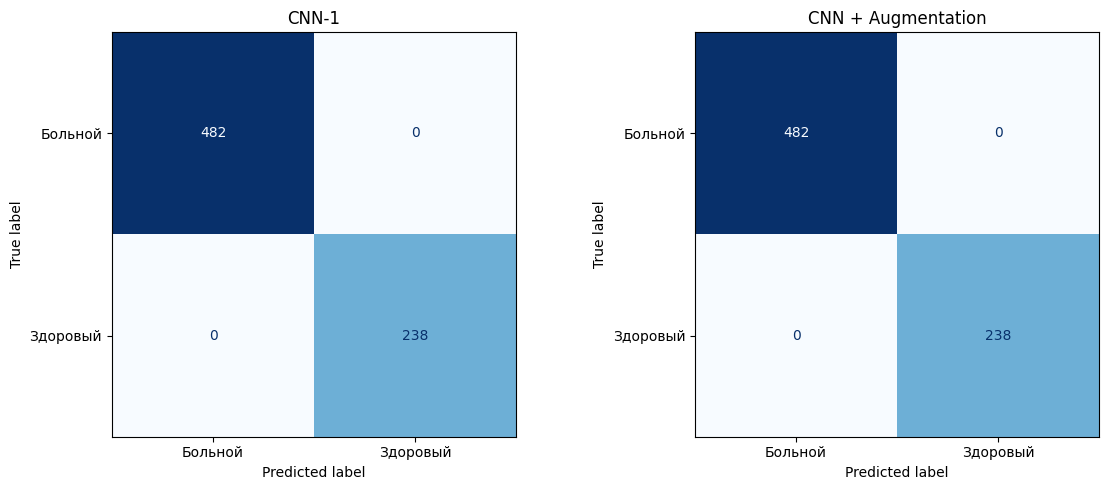

In [60]:


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, predictions) in zip(
    axes,
    binary_predictions.items()
):
    y_pred, y_prob = predictions

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        display_labels=["Больной", "Здоровый"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.savefig("binary_confusion_matrix.png", dpi=150)
plt.show()


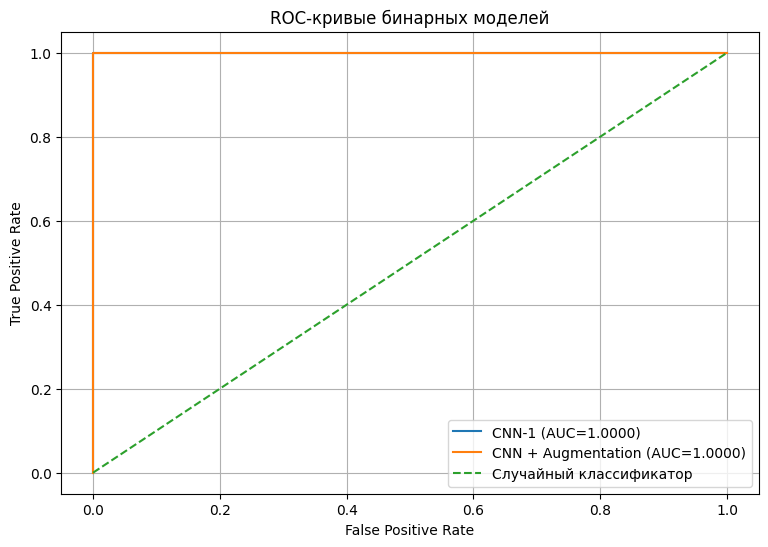

In [61]:


plt.figure(figsize=(9, 6))

for name, (y_pred, y_prob) in binary_predictions.items():

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_prob
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={roc_auc:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Случайный классификатор"
)

plt.title("ROC-кривые бинарных моделей")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.savefig("binary_roc.png", dpi=150)
plt.show()


In [62]:

final_results = binary_results.copy()

final_results["Val Accuracy"] = [
    max(history1.history["val_accuracy"]),
    max(history_aug.history["val_accuracy"])
]

final_results["Val Loss"] = [
    min(history1.history["val_loss"]),
    min(history_aug.history["val_loss"])
]

final_results["Эпох обучения"] = [
    len(history1.history["loss"]),
    len(history_aug.history["loss"])
]

final_results["Время (с)"] = [
    train_time1,
    train_time_aug
]

print(final_results.round(4).to_string(index=False))

final_results.to_csv(
    "binary_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nРезультаты сохранены в binary_results.csv")


            Модель  Accuracy  Precision  Recall  F1-score  ROC-AUC  Val Accuracy  Val Loss  Эпох обучения  Время (с)
             CNN-1       1.0        1.0     1.0       1.0      1.0           1.0    0.0006             11   661.1591
CNN + Augmentation       1.0        1.0     1.0       1.0      1.0           1.0    0.0020             13  1199.6446

Результаты сохранены в binary_results.csv


При сравнении архитектур наилучший результат показала CNN-1, достигшая точности 100% на валидационной выборке. Увеличение глубины сети в CNN-2 не привело к улучшению качества. Применение Dropout и L2-регуляризации в CNN-3 позволило немного повысить валидационную точность относительно CNN-2, но не превзойти CNN-1.

При добавлении аугментации валидационная точность осталась на уровне 100%. Однако время обучения увеличилось, а минимальное значение Validation Loss стало выше.

На полученной тестовой выборке обе бинарные модели показали ROC-AUC = 1,0. Для окончательной оценки качества также использовались Accuracy, Precision, Recall, F1-score и матрицы ошибок.